In [1]:
from pathlib import Path
import numpy as np
from scipy.io import loadmat
print("kernel working")



kernel working


In [6]:
data_dir=Path(r"C:\Users\lenovo\Desktop\Sathyaraj\sathya\data\cwru")
ouput_dir=Path(r"C:\Users\lenovo\Desktop\Sathyaraj\sathya\data\ouput")

In [7]:
mat_files = sorted(data_dir.glob('*.mat'))
print(len(mat_files))

40


sample 


In [8]:
sample_path = mat_files[0]
sample_data = loadmat(sample_path)
print(sample_data)

{'__header__': b'MATLAB 5.0 MAT-file, Platform: PCWIN, Created on: Mon Jan 31 13:55:05 2000', '__version__': '1.0', '__globals__': [], 'X118_DE_time': array([[-0.0027614 ],
       [-0.09632403],
       [ 0.11370459],
       ...,
       [-0.07829373],
       [-0.14911545],
       [ 0.02111657]], shape=(122571, 1)), 'X118_FE_time': array([[-0.24716182],
       [ 0.14279091],
       [ 0.00328727],
       ...,
       [ 0.01643636],
       [-0.03842   ],
       [-0.16806182]], shape=(122571, 1)), 'X118_BA_time': array([[ 0.01553163],
       [ 0.01693994],
       [-0.03645507],
       ...,
       [ 0.03178754],
       [-0.03243134],
       [-0.0668343 ]], shape=(122571, 1)), 'X118RPM': array([[1796]], dtype=uint16)}


In [9]:
LABELS = {'N': 0, 'IR': 1, 'OR': 2, 'B': 3}
CLASS_NAMES = {0: 'Normal', 1: 'Inner-race fault', 2: 'Outer-race fault', 3: 'Ball fault'}

def get_label(filename):
    name = filename.upper()
    if name.startswith('IR'):
        return LABELS['IR']
    if name.startswith('OR'):
        return LABELS['OR']
    if name.startswith('N'):
        return LABELS['N']
    if name.startswith('B'):
        return LABELS['B']
    raise ValueError(f'Unknown class in filename: {filename}')

for path in mat_files:
    print(f'{path.name:30} -> {get_label(path.name)} ({CLASS_NAMES[get_label(path.name)]})')

B007_0.mat                     -> 3 (Ball fault)
B007_1.mat                     -> 3 (Ball fault)
B007_2.mat                     -> 3 (Ball fault)
B007_3.mat                     -> 3 (Ball fault)
B014_0.mat                     -> 3 (Ball fault)
B014_1.mat                     -> 3 (Ball fault)
B014_2.mat                     -> 3 (Ball fault)
B014_3.mat                     -> 3 (Ball fault)
B021_0.mat                     -> 3 (Ball fault)
B021_1.mat                     -> 3 (Ball fault)
B021_2.mat                     -> 3 (Ball fault)
B021_3.mat                     -> 3 (Ball fault)
IR007_0.mat                    -> 1 (Inner-race fault)
IR007_1.mat                    -> 1 (Inner-race fault)
IR007_2.mat                    -> 1 (Inner-race fault)
IR007_3.mat                    -> 1 (Inner-race fault)
IR014_0.mat                    -> 1 (Inner-race fault)
IR014_1.mat                    -> 1 (Inner-race fault)
IR014_2.mat                    -> 1 (Inner-race fault)
IR014_3.mat                

1. X118_DE_time
Primary signal
These are vibration readings from the Drive End (DE) of the motor, near the shaft and bearing being tested.

Your sample contains 122,571 readings.

2. X118_FE_time

These are vibration readings from the Fan End (FE) of the motor.

This is another measurement location that can provide additional information about the motor's condition.

3. X118_BA_time

These are readings from the Base Accelerometer (BA) channel in this dataset. It provides another vibration measurement.


4. X118RPM

The motor's rotational speed. Your sample records 1,796 RPM.

This is a single operating-condition measurement, not a long sequence like the vibration signals.

In [10]:
from scipy.io import loadmat
import numpy as np

sample_path = mat_files[0]
mat_data = loadmat(sample_path)

for key, value in mat_data.items():
    if key.startswith("__"):
        continue

    array = np.asarray(value)

    print(f"\nVariable: {key}")
    print(f"Shape: {array.shape}")
    print(f"Data type: {array.dtype}")
    print(f"First 5 values:\n{array.flatten()[:5]}")


Variable: X118_DE_time
Shape: (122571, 1)
Data type: float64
First 5 values:
[-0.0027614  -0.09632403  0.11370459  0.25729725 -0.05831421]

Variable: X118_FE_time
Shape: (122571, 1)
Data type: float64
First 5 values:
[-0.24716182  0.14279091  0.00328727 -0.10683636  0.13601091]

Variable: X118_BA_time
Shape: (122571, 1)
Data type: float64
First 5 values:
[ 0.01553163  0.01693994 -0.03645507 -0.04474398  0.00772558]

Variable: X118RPM
Shape: (1, 1)
Data type: uint16
First 5 values:
[1796]


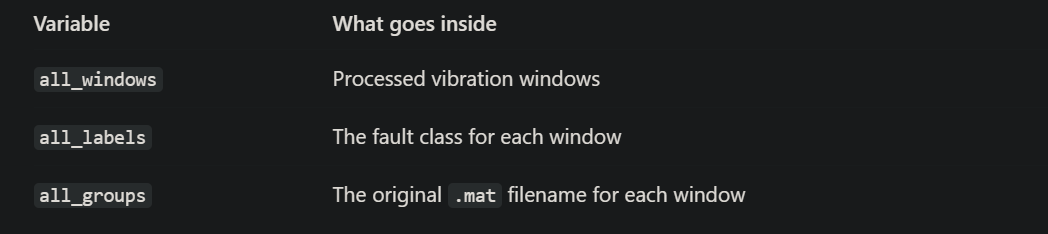

In [11]:
import numpy as np
from scipy.io import loadmat
from pathlib import Path

WINDOW_SIZE = 1024

all_windows = []
all_labels = []
all_groups = []

In [12]:
sample_path = mat_files[0]
mat_data = loadmat(sample_path)

de_keys = [
    key for key in mat_data
    if not key.startswith("__")
    and "DE_TIME" in key.upper()
]

print("File:", sample_path.name)
print("Drive-end variables:", de_keys)

File: B007_0.mat
Drive-end variables: ['X118_DE_time']


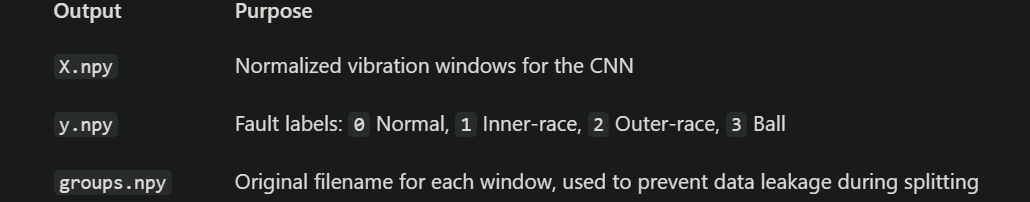

In [13]:

import numpy as np
from scipy.io import loadmat
from pathlib import Path

# 1. Configuration
WINDOW_SIZE = 1024
OUTPUT_DIR = Path("data/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Prepare collections
all_windows = []
all_labels = []
all_groups = []

print(f"Found {len(mat_files)} MATLAB files\n")

# 3. Process every MATLAB file
for path in mat_files:

    # Get fault label from the filename
    label = get_label(path.name)

    # Load MATLAB file
    mat_data = loadmat(path)

    # Find the drive-end vibration signal
    de_keys = [
        key for key in mat_data
        if not key.startswith("__")
        and "DE_TIME" in key.upper()
    ]

    if len(de_keys) != 1:
        raise ValueError(
            f"{path.name}: expected one DE signal, found {de_keys}"
        )

    # Extract vibration readings
    signal = np.asarray(
        mat_data[de_keys[0]]
    ).squeeze().astype(np.float32)

    if signal.ndim != 1 or len(signal) == 0:
        raise ValueError(
            f"{path.name}: invalid signal shape {signal.shape}"
        )

    # 4. Divide signal into windows of 1024 readings
    usable_length = (len(signal) // WINDOW_SIZE) * WINDOW_SIZE
    signal = signal[:usable_length]
    windows = signal.reshape(-1, WINDOW_SIZE)

    # 5. Normalize each window
    means = windows.mean(axis=1, keepdims=True)
    stds = windows.std(axis=1, keepdims=True)

    windows = (windows - means) / np.maximum(stds, 1e-8)

    # 6. Store windows, labels, and source filenames
    all_windows.append(windows)
    all_labels.extend([label] * len(windows))
    all_groups.extend([path.name] * len(windows))

    print(
        f"{path.name:30} | "
        f"{len(signal):>8,} readings | "
        f"{len(windows):>4} windows | "
        f"{CLASS_NAMES[label]}"
    )

# 7. Combine data from all files
X = np.concatenate(all_windows, axis=0)
y = np.asarray(all_labels, dtype=np.int64)
groups = np.asarray(all_groups)

# Add channel dimension for a 1D CNN
X = X[:, np.newaxis, :]

# 8. Validate the prepared dataset
assert X.ndim == 3
assert X.shape[1:] == (1, WINDOW_SIZE)
assert len(X) == len(y) == len(groups)
assert np.isfinite(X).all()
assert set(np.unique(y)).issubset({0, 1, 2, 3})

# 9. Display summary
print("\n" + "=" * 40)
print("PREPROCESSING COMPLETE")
print("=" * 40)

print("Total recordings:", len(mat_files))
print("Total windows:", len(X))
print("X shape:", X.shape)
print("y shape:", y.shape)
print("groups shape:", groups.shape)

print("\nClass distribution:")
unique_labels, counts = np.unique(y, return_counts=True)

for label, count in zip(unique_labels, counts):
    print(f"{CLASS_NAMES[int(label)]:20}: {count} windows")

# 10. Save the prepared dataset
np.save(OUTPUT_DIR / "X.npy", X)
np.save(OUTPUT_DIR / "y.npy", y)
np.save(OUTPUT_DIR / "groups.npy", groups)

print("\nSaved dataset to:", OUTPUT_DIR.resolve())
print("Files: X.npy, y.npy, groups.npy")


Found 40 MATLAB files

B007_0.mat                     |  121,856 readings |  119 windows | Ball fault
B007_1.mat                     |  120,832 readings |  118 windows | Ball fault
B007_2.mat                     |  120,832 readings |  118 windows | Ball fault
B007_3.mat                     |  120,832 readings |  118 windows | Ball fault
B014_0.mat                     |  120,832 readings |  118 windows | Ball fault
B014_1.mat                     |  121,856 readings |  119 windows | Ball fault
B014_2.mat                     |  121,856 readings |  119 windows | Ball fault
B014_3.mat                     |  121,856 readings |  119 windows | Ball fault
B021_0.mat                     |  121,856 readings |  119 windows | Ball fault
B021_1.mat                     |  120,832 readings |  118 windows | Ball fault
B021_2.mat                     |  121,856 readings |  119 windows | Ball fault
B021_3.mat                     |  121,856 readings |  119 windows | Ball fault
IR007_0.mat                  